In [1]:
import pandas as pd
import numpy as np

print("Restaurant Analysis Project Started!")

Restaurant Analysis Project Started!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings 
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

Saving 22_restaurant_orders.csv to 22_restaurant_orders.csv


In [5]:
df = pd.read_csv('22_restaurant_orders.csv')

df.head()
#it return the five row of the data set

,Order_ID,Order_Date,Restaurant_Name,Cuisine,Dish_Name,Category,Quantity,Unit_Price,Order_Hour,Delivery_Mode
0,FO000000,2025-08-31,Pizza Corner,Healthy,Pasta,Main Course,1.0,336.58,17,Dine-in
1,FO000001,2025-01-16,Green Bowl,Italian,Salad,Beverage,5.0,789.81,12,Dine-in
2,FO000002,2026-05-31,Tandoori House,Indian,Burger,Dessert,5.0,717.33,19,Delivery
3,FO000003,2025-01-05,Green Bowl,Healthy,Paneer Curry,Snack,2.0,484.37,15,Delivery
4,FO000004,2025-03-26,Pizza Corner,Indian,Burger,Dessert,5.0,482.80,8,Dine-in


In [6]:
# Number of rows and columns
print("Dataset Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns)

Dataset Shape: (862, 10)

Columns:
Index(['Order_ID', 'Order_Date', 'Restaurant_Name', 'Cuisine', 'Dish_Name',
       'Category', 'Quantity', 'Unit_Price', 'Order_Hour', 'Delivery_Mode'],
      dtype='object')


In [8]:
#Check the number of unique values:

print("Total Restaurants:", df['Restaurant_Name'].nunique())

print("Total Cuisines:", df['Cuisine'].nunique())

print("Total Dishes:", df['Dish_Name'].nunique())

print("Total Categories:", df['Category'].nunique())

print("Total Orders:", df['Order_ID'].nunique())

Total Restaurants: 5
Total Cuisines: 5
Total Dishes: 8
Total Categories: 4
Total Orders: 850


In [9]:
#SALES ANALYSIS

#Step 1: Calculate revenue

#Revenue = Quantity × Unit_Price
df['Revenue'] = df['Quantity'] * df['Unit_Price']

df.head()

,Order_ID,Order_Date,Restaurant_Name,Cuisine,Dish_Name,Category,Quantity,Unit_Price,Order_Hour,Delivery_Mode,Revenue
0,FO000000,2025-08-31,Pizza Corner,Healthy,Pasta,Main Course,1.0,336.58,17,Dine-in,336.58
1,FO000001,2025-01-16,Green Bowl,Italian,Salad,Beverage,5.0,789.81,12,Dine-in,3949.05
2,FO000002,2026-05-31,Tandoori House,Indian,Burger,Dessert,5.0,717.33,19,Delivery,3586.65
3,FO000003,2025-01-05,Green Bowl,Healthy,Paneer Curry,Snack,2.0,484.37,15,Delivery,968.74
4,FO000004,2025-03-26,Pizza Corner,Indian,Burger,Dessert,5.0,482.80,8,Dine-in,2414.00


In [10]:
#Step 2: Calculate important sales metrics
total_revenue = df['Revenue'].sum()

total_quantity = df['Quantity'].sum()

total_orders = df['Order_ID'].nunique()

average_order_value = (
    df.groupby('Order_ID')['Revenue'].sum().mean()
)

print("Total Revenue:", round(total_revenue, 2))

print("Total Quantity Sold:", total_quantity)

print("Total Orders:", total_orders)

print("Average Order Value:", round(average_order_value, 2))

Total Revenue: 1190349.76
Total Quantity Sold: 2497.0
Total Orders: 850
Average Order Value: 1400.41


In [12]:
restaurant_sales = (
    df.groupby('Restaurant_Name')['Revenue']
    .sum()
    .sort_values(ascending=False)
)

print(restaurant_sales)

Restaurant_Name
Urban Cafe        252238.49
Spice Hub         248946.57
Pizza Corner      247681.12
Green Bowl        236608.80
Tandoori House    204874.78
Name: Revenue, dtype: float64


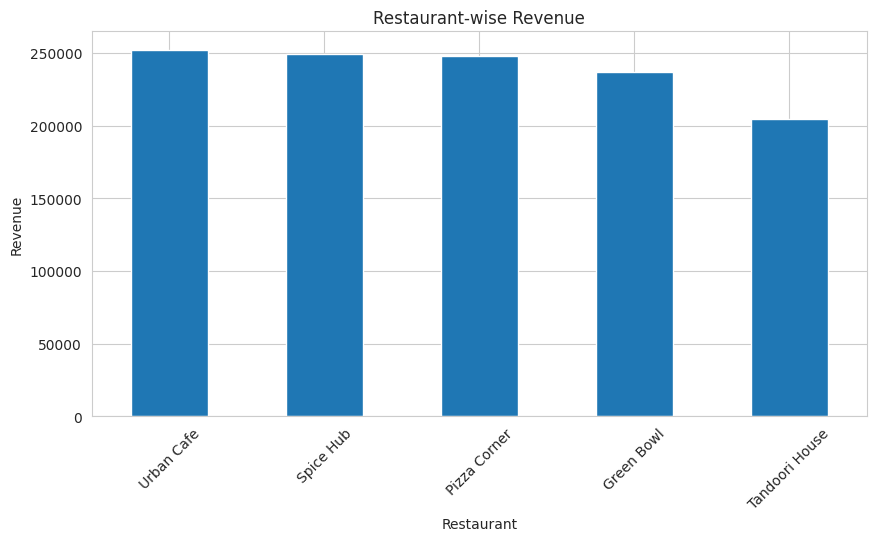

In [13]:
plt.figure(figsize=(10,5))

restaurant_sales.plot(kind='bar')

plt.title('Restaurant-wise Revenue')
plt.xlabel('Restaurant')
plt.ylabel('Revenue')

plt.xticks(rotation=45)

plt.show()

In [14]:
#MENU ANALYSIS

#Most popular dishes

popular_dishes = (
    df.groupby('Dish_Name')['Quantity']
    .sum()
    .sort_values(ascending=False)
)

print(popular_dishes)

Dish_Name
Pasta           346.0
Noodles         332.0
Biryani         325.0
Pizza           315.0
Tacos           309.0
Salad           302.0
Burger          301.0
Paneer Curry    267.0
Name: Quantity, dtype: float64


Dish_Name
Pasta           346.0
Noodles         332.0
Biryani         325.0
Pizza           315.0
Tacos           309.0
Salad           302.0
Burger          301.0
Paneer Curry    267.0
Name: Quantity, dtype: float64


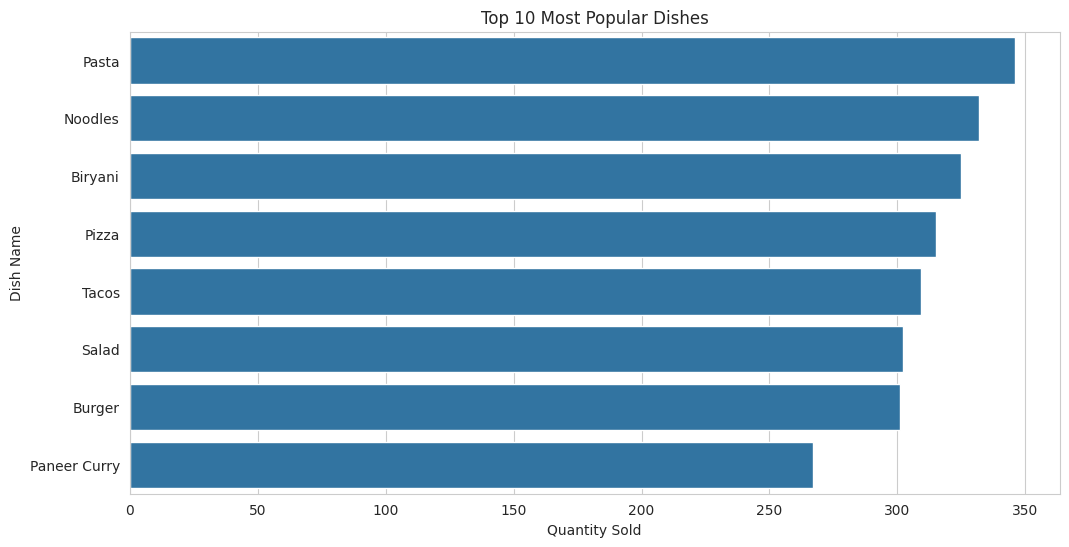

In [15]:
#Top 10 dishes:

popular_dishes = (
    df.groupby('Dish_Name')['Quantity']
    .sum()
    .sort_values(ascending=False)
)

print(popular_dishes)



top_10_dishes = popular_dishes.head(10)

plt.figure(figsize=(12,6))

sns.barplot(
    x=top_10_dishes.values,
    y=top_10_dishes.index
)

plt.title('Top 10 Most Popular Dishes')
plt.xlabel('Quantity Sold')
plt.ylabel('Dish Name')

plt.show()

In [16]:
#Category analysis



category_sales = df.groupby('Category').agg({
    'Quantity': 'sum',
    'Revenue': 'sum'
})

print(category_sales)

             Quantity    Revenue
Category                        
Beverage        614.0  288703.90
Dessert         598.0  300391.85
Main Course     594.0  263578.86
Snack           691.0  337675.15


In [18]:
#RESTAURANT PERFORMANCE ANALYSIS
#Step 1: Compare restaurant performance
restaurant_analysis = df.groupby('Restaurant_Name').agg({

    'Order_ID': 'nunique',

    'Quantity': 'sum',

    'Revenue': 'sum'

})

restaurant_analysis.columns = [
    'Total_Orders',
    'Total_Quantity',
    'Total_Revenue'
]

print(restaurant_analysis)

                 Total_Orders  Total_Quantity  Total_Revenue
Restaurant_Name                                             
Green Bowl                163           499.0      236608.80
Pizza Corner              173           505.0      247681.12
Spice Hub                 170           501.0      248946.57
Tandoori House            163           468.0      204874.78
Urban Cafe                181           524.0      252238.49
